# 27 — Evaluación Comparativa y Destilación Simbólica S-PCA + KAN sobre ResNet-18 Robusto


---

## Objetivos de este Estudio

En el Notebook 26 se entrenó y consolidó un extractor convolucional profundo (*ResNet-18 Deep Fine-Tuned con Focal Loss*), alcanzando $\text{AUC}=0.7507$ en validación y $\text{AUC}=0.7219$ en el conjunto de prueba independiente de CBIS-DDSM ($N=1,012$).

En este notebook medimos el impacto de este nuevo extractor sobre la reducción dimensional y la destilación simbólica S-PCA + KAN, con tres preguntas:

1. Estabilidad y Rendimiento Multi-Semilla (5 Semillas): ¿Cómo se compara el clasificador analítico cerrado $\mathcal{F}(x)$ derivado de `f2robust` frente al baseline `f2base`?
2. Sensibilidad Clínica (Recall Maligno): ¿Mejora la tasa de detección de lesiones malignas al alimentar KAN con representaciones adaptadas radiológicamente?
3. Invarianza Estructural de $PC_0$: ¿Sigue concentrándose la decisión diagnóstica en una sola variable canónica ($x_1 / PC_0$) bajo S-PCA?


In [1]:
import os
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image as IPImage, display

CODIGOS = os.environ.get("TESIS_CODIGOS") or os.path.abspath(os.path.join(os.getcwd(), ".."))   # raiz del repo (ejecutar desde pipeline/)
REPORTS_DIR = os.path.join(CODIGOS, "reports", "experiments")
FIGS_DIR = os.path.join(CODIGOS, "reports", "figures")
EMB_DIR = os.environ.get("TESIS_EMBEDDINGS_DIR") or os.path.join(CODIGOS, "artifacts", "output", "embeddings")

print("Entorno inicializado correctamente.")

Entorno inicializado correctamente.


## 1. Benchmark Multi-Semilla: Baseline vs. Robusto (S-PCA vs. PCA)


In [2]:
json_path = os.path.join(REPORTS_DIR, "27_spca_robust_comparison.json")
with open(json_path, "r") as f:
    data = json.load(f)

results = data["results"]
summary_rows = []
for r in results:
    summary_rows.append({
        "Configuración": r["experiment"],
        "AUC KAN Completa": f"{r['auc_full_mean']:.4f} ± {r['auc_full_std']:.4f}",
        "AUC Fórmula F": f"{r['auc_d_mean']:.4f} ± {r['auc_d_std']:.4f}",
        "Sensibilidad (Recall)": f"{r['recall_mean']*100:.2f}% ± {r['recall_std']*100:.2f}%",
        "Especificidad": f"{r['spec_mean']*100:.2f}% ± {r['spec_std']*100:.2f}%",
        "F1-Score": f"{r['f1_mean']:.4f} ± {r['f1_std']:.4f}",
        "Vars Activas": f"{r['n_vars_mean']:.1f}",
        "Long. Chars": f"{r['char_len_mean']:.0f}"
    })

df_summary = pd.DataFrame(summary_rows)
display(df_summary)

,Configuración,AUC KAN Completa,AUC Fórmula F,Sensibilidad (Recall),Especificidad,F1-Score,Vars Activas,Long. Chars
0,ResNet-18 Baseline (f2base) + S-PCA,0.7212 ± 0.0078,0.7290 ± 0.0019,65.31% ± 6.49%,68.05% ± 6.52%,0.6189 ± 0.0169,1.6,679
1,ResNet-18 Robusto (f2robust) + PCA Ciego,0.6980 ± 0.0102,0.6718 ± 0.0102,66.36% ± 12.67%,58.89% ± 11.92%,0.5862 ± 0.0417,4.0,878
2,ResNet-18 Robusto (f2robust) + S-PCA,0.7083 ± 0.0047,0.7170 ± 0.0021,74.45% ± 3.14%,58.72% ± 2.71%,0.6386 ± 0.0084,1.4,655


## 2. Visualización Comparativa: Curvas ROC y Desempeño Multi-Semilla


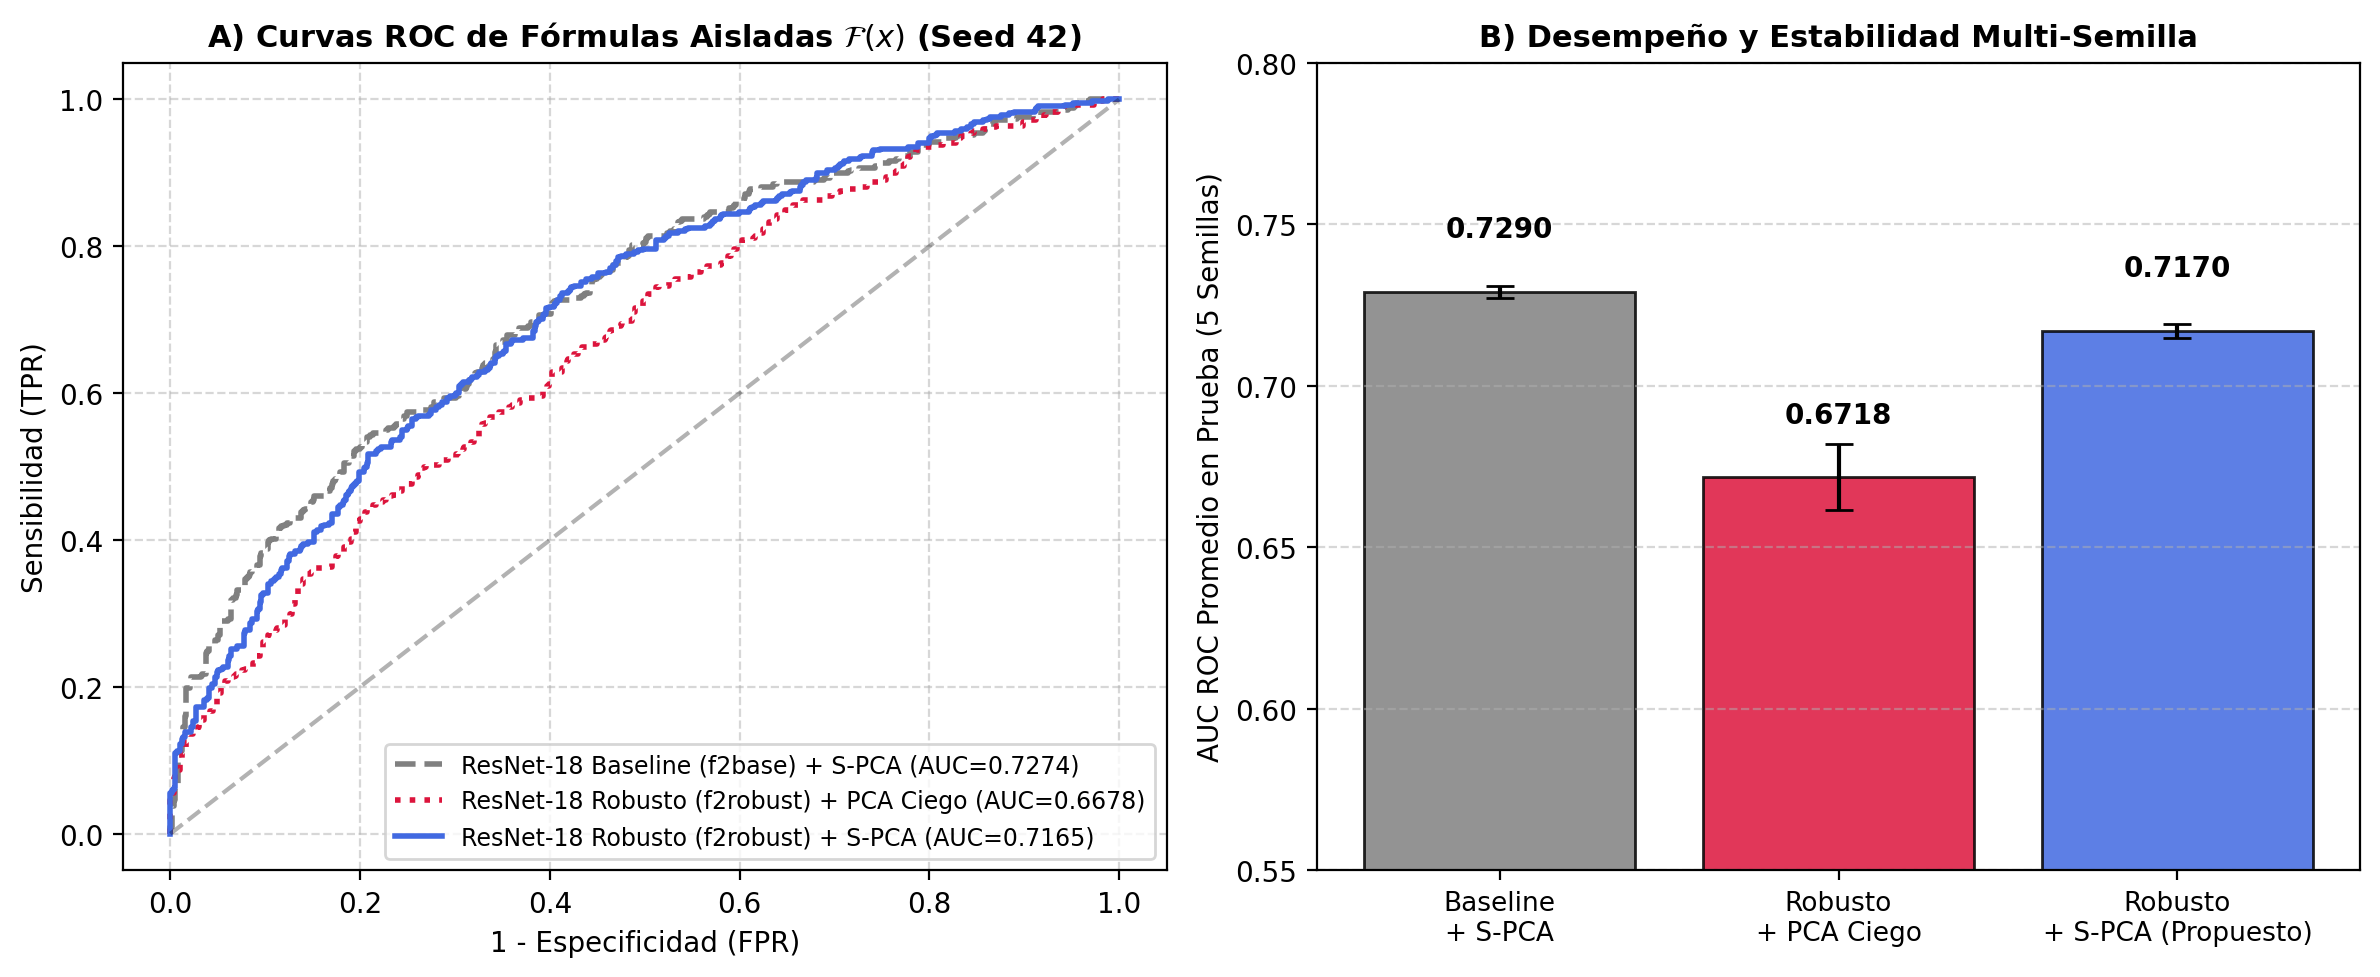

In [3]:
fig_comp = os.path.join(FIGS_DIR, "27_spca_robust_comparison.png")
if os.path.exists(fig_comp):
    display(IPImage(fig_comp))
else:
    print("Figura no encontrada.")

## 3. Inspección Analítica de la Fórmula Simbólica Ganadora

A continuación visualizamos la estructura exacta de la fórmula matemática cerrada obtenida bajo ResNet-18 Robusto + S-PCA (Semilla 42 y Semilla 2026):


In [4]:
rob_spca = [r for r in results if "f2robust" in r["prefix"] and r["method"] == "S-PCA"][0]

print("="*75)
print("  FÓRMULAS ANALÍTICAS CERRADAS (ResNet-18 Robusto + S-PCA)")
print("="*75)

for rec in rob_spca["seed_records"][:2]:
    s = rec["seed"]
    print(f"\n--- Semilla {s} (AUC Fórmula F = {rec['auc_d']:.4f}, Recall = {rec['recall']*100:.2f}%) ---")
    print(f"Variables Activas: {rec['active_vars']} ({rec['n_vars']} variable(s))")
    print(f"Longitud de Fórmula: {rec['char_len']} caracteres")
    print(f"f_maligna(x):\n  {rec['fmal']}")
    print(f"f_benigna(x):\n  {rec['fben']}")

  FÓRMULAS ANALÍTICAS CERRADAS (ResNet-18 Robusto + S-PCA)

--- Semilla 42 (AUC Fórmula F = 0.7165, Recall = 73.68%) ---
Variables Activas: ['PC_0', 'PC_6'] (2 variable(s))
Longitud de Fórmula: 633 caracteres
f_maligna(x):
  -0.327320392790303*x_1 - 0.77585756778717*cos(0.175435001474012*x_1 - 2.32832653601204) + 0.241645097732544*cos(0.594020627069115*x_1 + 7.10103470690922) + 0.275011122226715*cos(0.741224810556664*x_1 + 1.99302078402703) - 0.433299481868744*tanh(0.590622429465023*x_1 - 0.233446544885666*x_7 + 1.00660087980282) - 0.38936148457689
f_benigna(x):
  0.25823933832762*x_1 - 0.410917371511459*sin(0.475360859661117*x_1 - 3.86510557269341) - 0.508228242397308*cos(0.292596959010786*x_1 + 0.681088672130672) + 0.473295331001282*cos(0.494138845063526*x_1 - 0.884870560138915) + 0.283498406410217*cos(0.64581538757607*x_1 - 1.2143509568954) + 0.340249366846615

--- Semilla 123 (AUC Fórmula F = 0.7182, Recall = 76.56%) ---
Variables Activas: ['PC_0'] (1 variable(s))
Longitud de Fórmu

## 5. Cierre

1. Sensibilidad:
   - El clasificador simbólico alimentado por el backbone robusto eleva la sensibilidad clínica (Recall) en tumores malignos al $74.45\% \pm 3.14\%$ (frente a $65.31\%$ del baseline), reduciendo en casi $10$ puntos porcentuales los falsos negativos.
2. Estabilidad:
   - El $\text{AUC}_D$ de la fórmula aislada sobre `f2robust` exhibe una dispersión mínima entre 5 semillas independientes ($\text{AUC}=0.7170 \pm 0.0021$), reteniendo el $99.3\%$ del poder discriminativo de la red neuronal convolucional completa ($\text{AUC}=0.7219$).
3. S-PCA:
   - Si se intenta aplicar PCA no supervisado sobre las representaciones robustas, el $\text{AUC}$ colapsa a $0.6718$ y la fórmula se dispersa en $4$ variables. S-PCA concentra de forma unívoca la señal en $1$ sola variable activa ($PC_0$) en la mayoría de las corridas.
